# Time Series: Advanced Assignment Part 4
## Recovering Sinusoidal wave using RNN

Student Name(s): Cleo Joe Rheikel Sinuhaji, Federico Casarin    

Group No: 15



### Load required packages

In [121]:
# Import the needed packages
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN
import math
import random
from sklearn.metrics import mean_squared_error

In [122]:
# Fix the random seed
np.random.seed(0)

In [123]:
# Set the length of the series
n=3000
t=np.arange(0,n)
t.shape

(3000,)

### Generate Dataset
To generate dataset we will use the following function:
$f(t)=sin(0.02t)+cos(0.05t)+sin(0.06t)$  
The following is the graph of above. 
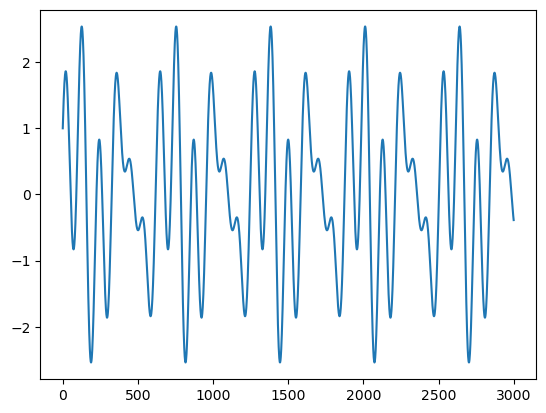

### Adding Noise
The data is very smooth. Your task is to add noise to data. You add noise by two ways:
- Uniform noise with low value -1 and high value 1
- Noise generate using normal distribution

**Note:** You will have two different datasets so you need to train two different model for comparitive study. 

In [124]:
# Your code here
dataset = np.sin(t*0.02) + np.cos(t*0.05) + np.sin(t*0.06)
noisy_dataset = dataset + np.random.uniform(-1, 1, size=n)
noisy_normal  = dataset + np.random.normal(0, 1/np.sqrt(3), size=n)


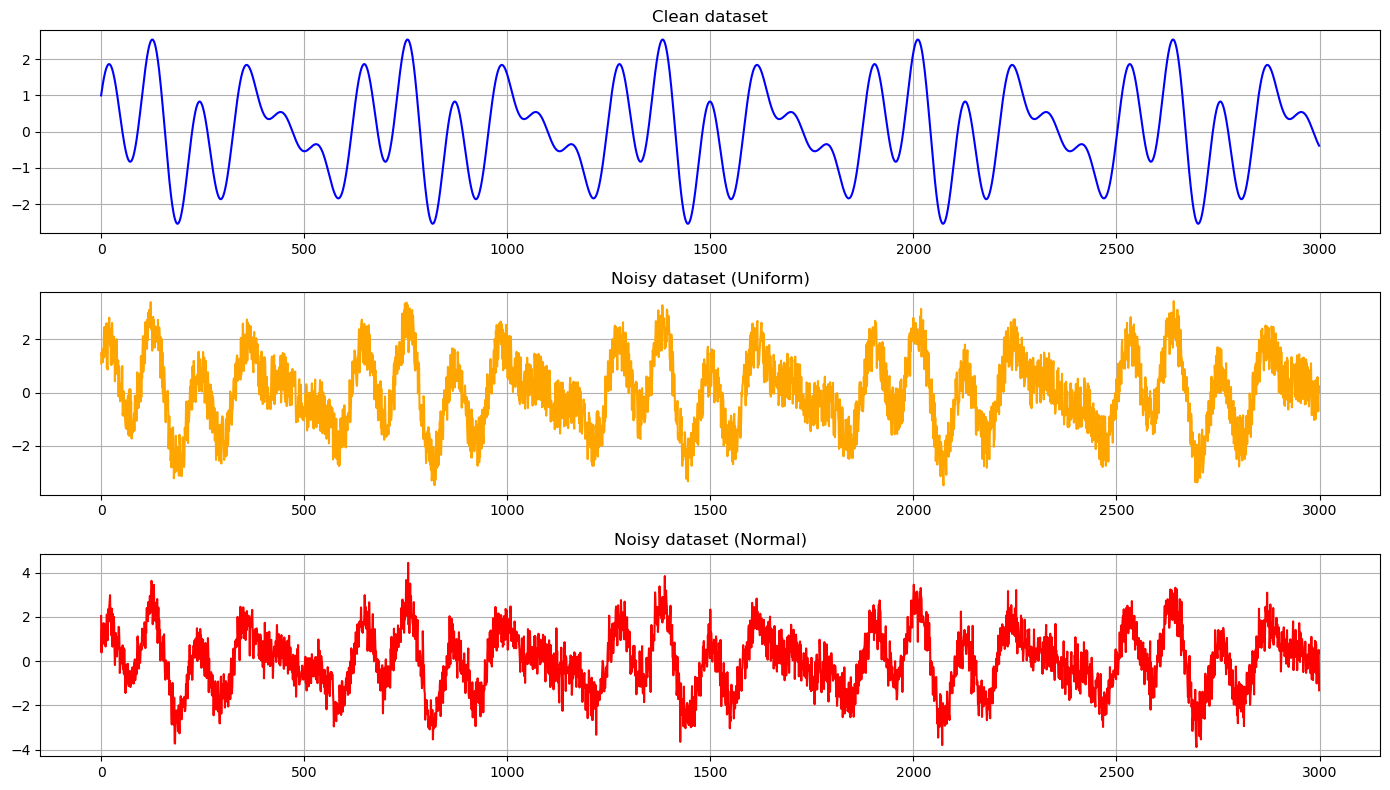

In [125]:
# Plot the original signal alog with noisy signal.
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 8))

# Plot the clean signal
ax1.plot(t, dataset, color='blue')
ax1.set_title("Clean dataset")
ax1.grid(True)

ax2.plot(t, noisy_dataset, color='orange')
ax2.set_title("Noisy dataset (Uniform)")
ax2.grid(True)

ax3.plot(t, noisy_normal, color='red')
ax3.set_title("Noisy dataset (Normal)")
ax3.grid(True)

plt.tight_layout() 
plt.show()

In [126]:
# Normalize your data using minmax scalar

scaler = MinMaxScaler(feature_range=(0, 1))
data_u = scaler.fit_transform(noisy_dataset.reshape(-1, 1)).flatten()
data_u


array([0.66181131, 0.72126999, 0.6997591 , ..., 0.40256232, 0.54095071,
       0.5043434 ], shape=(3000,))

In [127]:
# Split data into train and test set
idx = int(len(data_u) * 0.8)
print(idx)
train, test = data_u[:idx], data_u[idx:]



2400


In [128]:
def createDataset(data, step):
    X, Y =[], []
    for i in range(len(data)-step): 
        X.append(data[i:i+step])
        Y.append(data[i+step])
    return np.array(X), np.array(Y)
 
step = 10
trainX,trainY = createDataset(train,step)
testX,testY = createDataset(test,step)
print(trainX[0])

[0.66181131 0.72126999 0.6997591  0.69358853 0.668656   0.74250682
 0.69141609 0.83125715 0.86005144 0.69979714]


In [129]:
trainX = trainX.reshape((trainX.shape[0], step, 1)) # format in
testX  = testX.reshape((testX.shape[0], step, 1))


## RNN Model
Create a RNN model with the following paramters:
- Activation "tanh"
- Loss "mean squared error"
- optimizer "rmsprop"
- epochs 200
- batch size 16

In [130]:
# your code here
model = Sequential()
model.add(SimpleRNN(32, input_shape=(step, 1), activation='tanh'))
model.add(Dense(1))

model.compile(optimizer="rmsprop", loss='mse')
history = model.fit(trainX, trainY, epochs=200, batch_size=16, validation_data=(testX,testY))


Epoch 1/200


/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0299 - val_loss: 0.0249
Epoch 2/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 813us/step - loss: 0.0116 - val_loss: 0.0127
Epoch 3/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 826us/step - loss: 0.0103 - val_loss: 0.0096
Epoch 4/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 899us/step - loss: 0.0100 - val_loss: 0.0095
Epoch 5/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 828us/step - loss: 0.0097 - val_loss: 0.0104
Epoch 6/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 799us/step - loss: 0.0098 - val_loss: 0.0094
Epoch 7/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0097 - val_loss: 0.0094
Epoch 8/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0095 - val_loss: 0.0093
Epoch 9/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0095 - val_loss: 0.0129
Epoch 10/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0095 - val_loss: 0.0095
Epoch 11/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0095 - val_loss: 0.0093
Epoch 12/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0

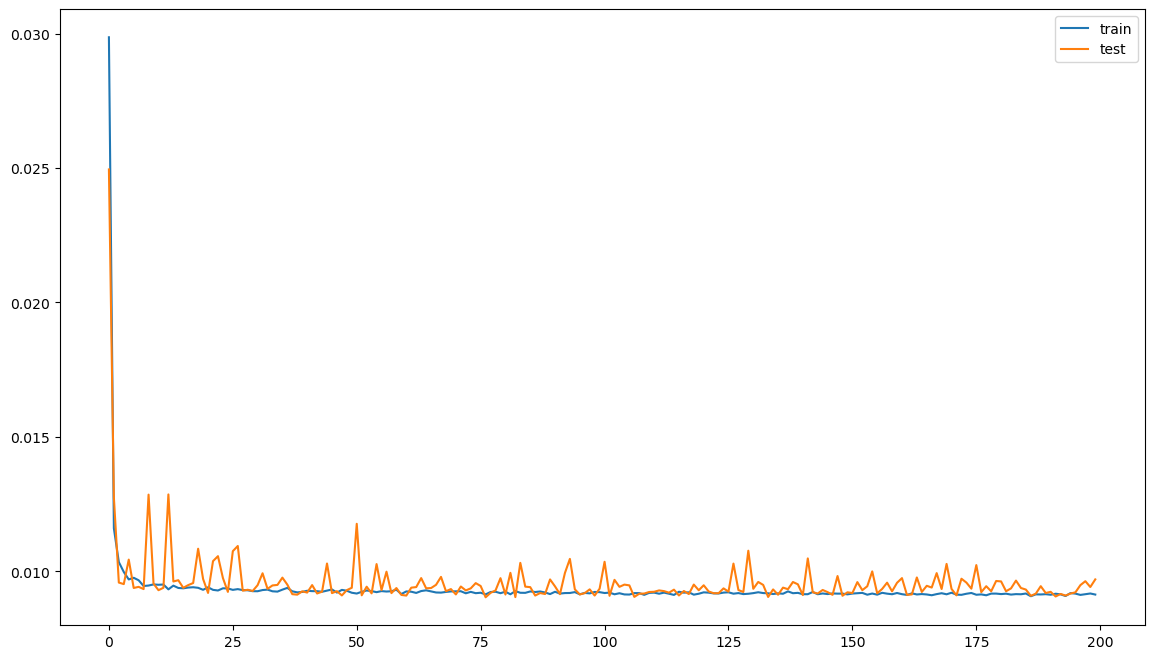

In [131]:
# Plot the loss
plt.figure(figsize=(14, 8))
plt.plot(history.history['loss'], label="train")
plt.plot(history.history['val_loss'], label="test")
plt.legend()
plt.show()

In [132]:
# Predict using test data
pred = model.predict(testX)
pred_inv = scaler.inverse_transform(pred).flatten()
testY_inv = scaler.inverse_transform(testY.reshape(-1, 1)).flatten()
clean_test = dataset[idx+step:]


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


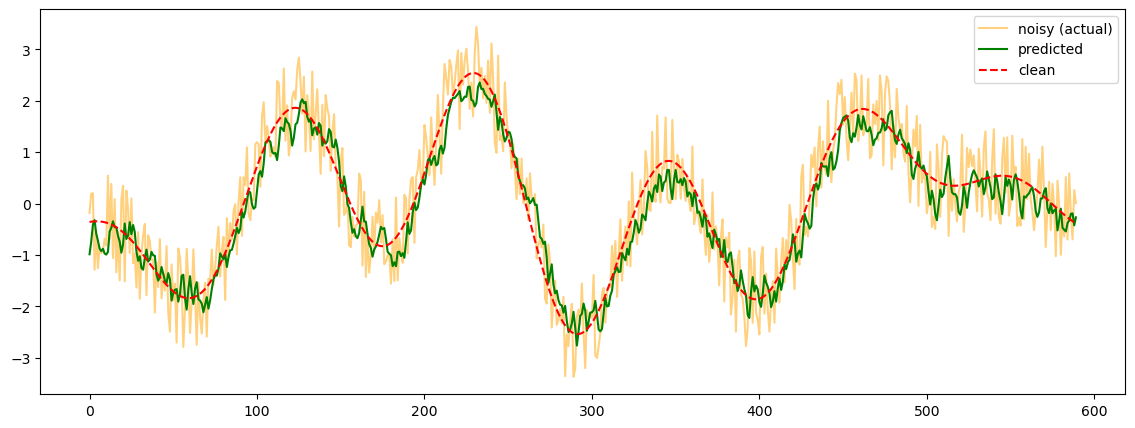

RMSE: 0.682


In [133]:
# Plot noisy data with the predicted data

plt.figure(figsize=(14, 5))
plt.plot(testY_inv, color='orange', alpha=0.5, label='noisy (actual)')
plt.plot(pred_inv, color='green', label='predicted')
plt.plot(clean_test, color='red', linestyle='--', label='clean')
plt.legend(); 
plt.show()

rmse = np.sqrt(mean_squared_error(testY_inv, pred_inv))
print("RMSE: %.3f" % rmse)

## Compare model for different datasets
Now it is time to compare the models. You can compare them based on different criterion inclusing their accuracy, training time or any other criteria. 

In [134]:

noisy_normal_scaled = scaler.fit_transform(noisy_normal.reshape(-1, 1)).flatten()


In [135]:
train, test = noisy_normal_scaled[:idx], noisy_normal_scaled[idx:]

trainX, trainY = createDataset(train, 10)
testX, testY = createDataset(test, 10) 

In [136]:
# your code here
model = Sequential()
model.add(SimpleRNN(32, input_shape=(step, 1), activation='tanh'))
model.add(Dense(1))

model.compile(optimizer="rmsprop", loss='mse')
history = model.fit(trainX, trainY, epochs=200, batch_size=16, validation_data=(testX,testY))


Epoch 1/200


/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0092 - val_loss: 0.0098
Epoch 2/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 743us/step - loss: 0.0069 - val_loss: 0.0089
Epoch 3/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 734us/step - loss: 0.0066 - val_loss: 0.0062
Epoch 4/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 726us/step - loss: 0.0065 - val_loss: 0.0084
Epoch 5/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 738us/step - loss: 0.0064 - val_loss: 0.0067
Epoch 6/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 733us/step - loss: 0.0064 - val_loss: 0.0064
Epoch 7/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 730us/step - loss: 0.0063 - val_loss: 0.0062
Epoch 8/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 723us/step - loss: 0.0064 - val_loss: 0.0063
Epoch 9/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 748us/step - loss: 0.0063 - val_loss: 0.0092
Epoch 10/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 737us/step - loss: 0.0063 - val_loss: 0.0097
Epoch 11/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 726us/step - loss: 0.0063 - val_loss: 0.0086
Epoch 12/200
150/150 ━━━━━━━━━━━━

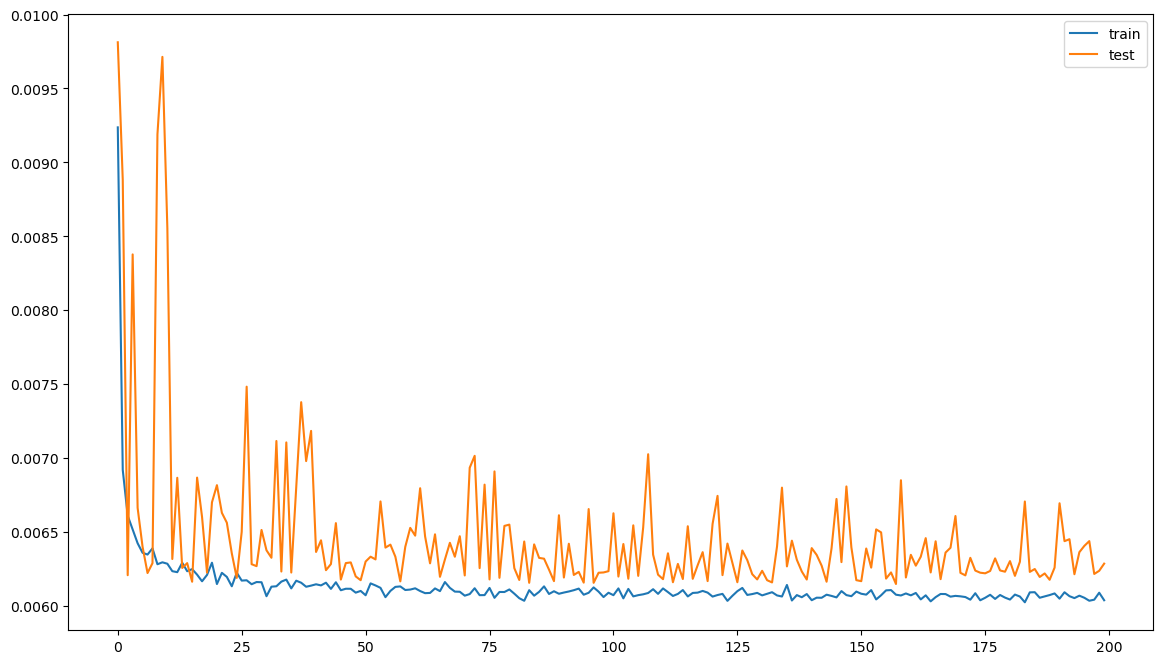

In [137]:
# Plot the loss
plt.figure(figsize=(14, 8))
plt.plot(history.history['loss'], label="train")
plt.plot(history.history['val_loss'], label="test")
plt.legend()
plt.show()

In [138]:
pred = model.predict(testX)
pred_inv = scaler.inverse_transform(pred).flatten()
testY_inv = scaler.inverse_transform(testY.reshape(-1, 1)).flatten()   # add this



19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


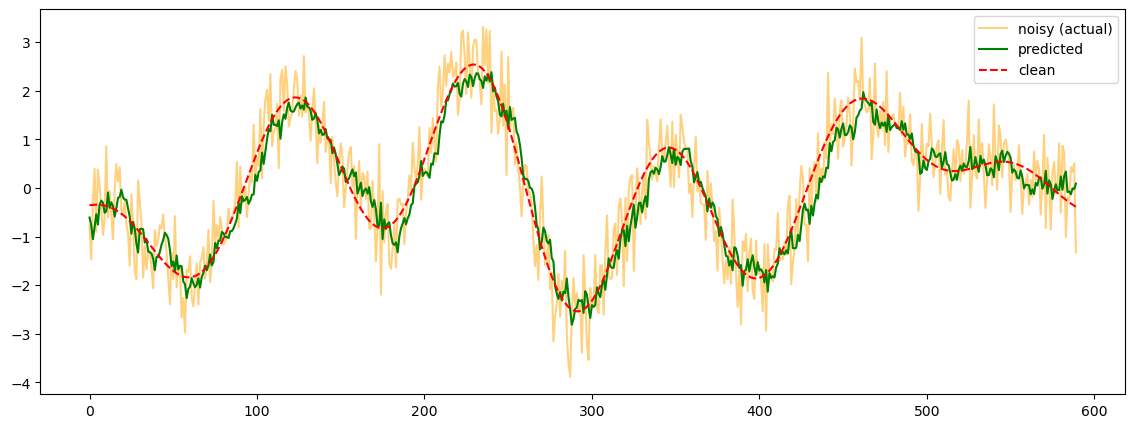

RMSE: 0.660


In [139]:
# Plot noisy data with the predicted data

plt.figure(figsize=(14, 5))
plt.plot(testY_inv, color='orange', alpha=0.5, label='noisy (actual)')
plt.plot(pred_inv, color='green', label='predicted')
plt.plot(clean_test, color='red', linestyle='--', label='clean')
plt.legend(); 
plt.show()

rmse = np.sqrt(mean_squared_error(testY_inv, pred_inv))
print("RMSE: %.3f" % rmse)

The added noise has an s.d. of around 0.577 which is the minimum threshold of the RMSE of the model (as these noise cannot be predicted). Both models achieve RMSE of around 0.65 - 0.67, so they capture most of the predictable component.

## CNN LSTM
Repeat the exercises with the noisy data (only of the dataset should be sufficient). 

In [107]:
# Your code here (you might need more cells so add as many as you like)
from tensorflow.keras.layers import LSTM
model = Sequential()
model.add(LSTM(50, input_shape=(10, 1)))
model.add(Dense(1))
model.summary()

model.compile(optimizer="rmsprop", loss='mse')
history = model.fit(trainX, trainY, epochs=200, batch_size=16, validation_data=(testX,testY))


/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0158 - val_loss: 0.0094
Epoch 2/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0100 - val_loss: 0.0096
Epoch 3/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0099 - val_loss: 0.0093
Epoch 4/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0097 - val_loss: 0.0101
Epoch 5/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0096 - val_loss: 0.0092
Epoch 6/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0095 - val_loss: 0.0122
Epoch 7/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0095 - val_loss: 0.0090
Epoch 8/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0094 - val_loss: 0.0090
Epoch 9/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0093 - val_loss: 0.0102
Epoch 10/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0094 - val_loss: 0.0091
Epoch 11/200
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0094 - val_loss: 0.0091
Epoch 12/200
150/150 ━━━━━━━━━━━━━━━━━━━━

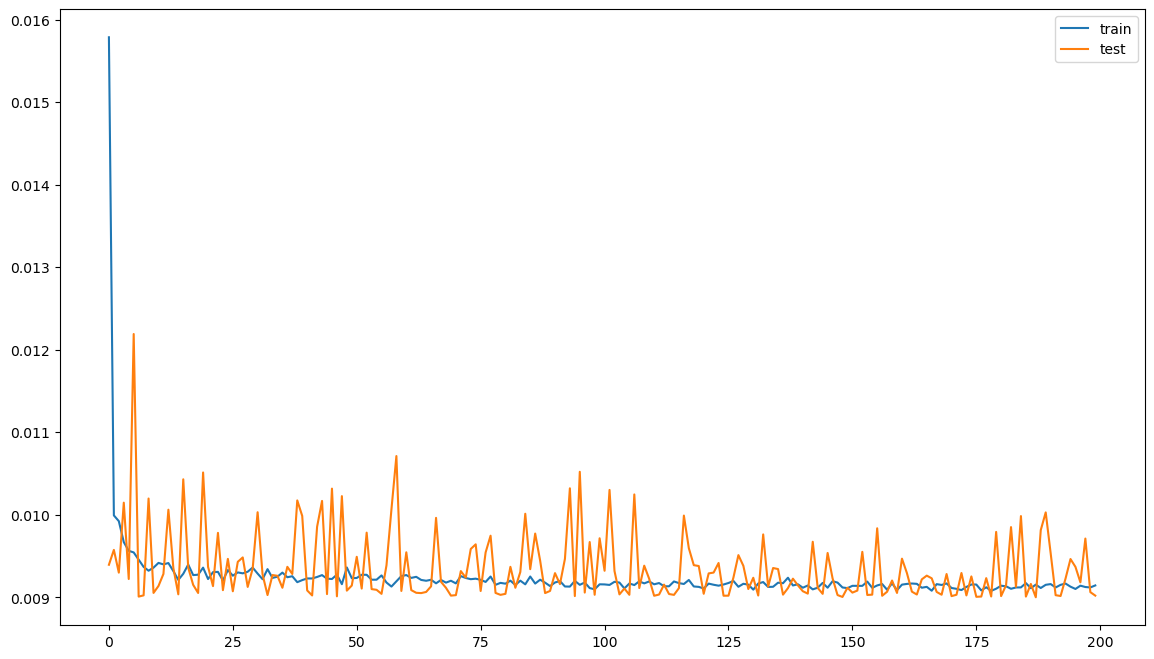

In [108]:
# Plot the loss
plt.figure(figsize=(14, 8))
plt.plot(history.history['loss'], label="train")
plt.plot(history.history['val_loss'], label="test")
plt.legend()
plt.show()

In [105]:
pred = model.predict(testX)
pred_inv = scaler.inverse_transform(pred).flatten()


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


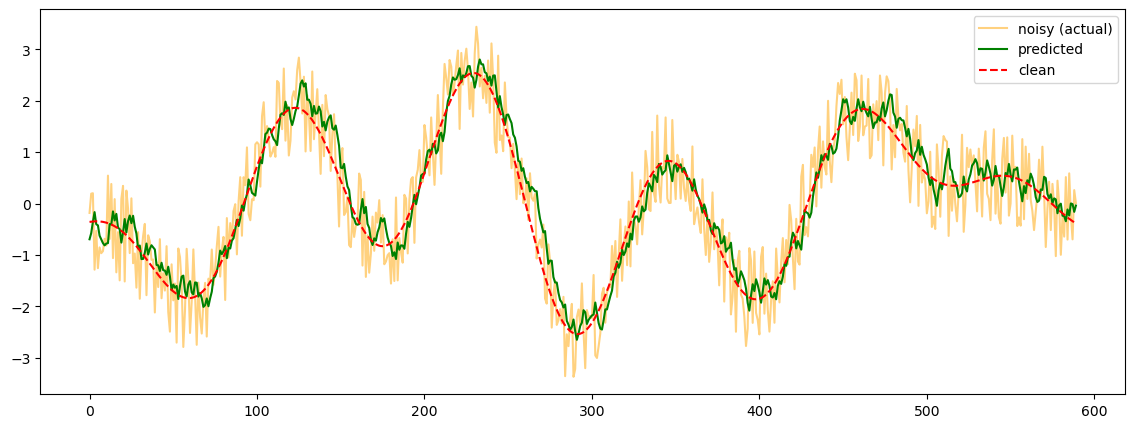

RMSE: 0.662


In [106]:
plt.figure(figsize=(14, 5))
plt.plot(testY_inv, color='orange', alpha=0.5, label='noisy (actual)')
plt.plot(pred_inv, color='green', label='predicted')
plt.plot(clean_test, color='red', linestyle='--', label='clean')
plt.legend(); 
plt.show()

rmse = np.sqrt(mean_squared_error(testY_inv, pred_inv))
print("RMSE: %.3f" % rmse)

Our RMSE is above 0.577 (form the added noise) therefore the model is performing well.